# How few numbers does it take to keep a photo?

Compressing a photograph with the singular value decomposition (SVD): how much of the image survives when only the strongest components are kept?

**Authors:** Ido Shalom, Daniel Rodan

## The photo as a matrix, and how far it can be compressed

### Section A

In [1]:
from PIL import Image

# Open the image file
image_path = 'data/Cliff_beach_BOEM_gov.jpg'  
image = Image.open(image_path)


# Get the dimensions of the image
width, height = image.size

# Display the dimensions
print(f'Dimensions of the image: Width = {width} pixels, Height = {height} pixels')

Dimensions of the image: Width = 2746 pixels, Height = 1830 pixels



**What are the dimensions of the image, and what does each dimension in the data matrix represent?**

- The "Height" dimension corresponds to the number of rows in the image (1,830), with each row representing a horizontal line of pixels from top to bottom.

- The "Width" dimension corresponds to the number of columns in the image (2,746), with each column representing a vertical line of pixels from left to right.

- A third dimension (3) represents the color channels of the image, typically corresponding to Red, Green, and Blue (RGB).

### Section B

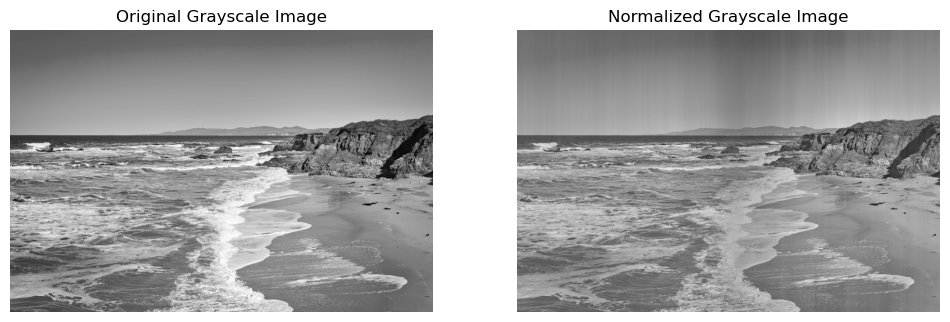

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# Convert the image to grayscale
gray_image = image.convert('L')

# Convert grayscale image to numpy array
gray_array = np.array(gray_image)

# Standardize the data
scaler = StandardScaler()
normalized_gray_array = scaler.fit_transform(gray_array)

# Convert normalized array back to image
normalized_gray_image = Image.fromarray(((normalized_gray_array - normalized_gray_array.min()) / (normalized_gray_array.max() - normalized_gray_array.min()) * 255).astype(np.uint8))

# Display the original grayscale image and the normalized grayscale image
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Original grayscale image
axes[0].imshow(gray_image, cmap='gray')
axes[0].set_title('Original Grayscale Image')
axes[0].axis('off')

# Normalized grayscale image
axes[1].imshow(normalized_gray_image, cmap='gray')
axes[1].set_title('Normalized Grayscale Image')
axes[1].axis('off')

plt.show()


**Does the normalization change the quality of the image?**

It seems like the images does have some difference between them, the normalization did harm a bit to the quality of the image.

### Section C

In [3]:
# Perform SVD on the normalized image
U, S, Vt = np.linalg.svd(normalized_gray_array, full_matrices=False)

# Number of singular values
num_singular_values = len(S)
print(f'Number of singular values: {num_singular_values}')

Number of singular values: 1830


**Why do we get 1,830 singular values?**

As we learned in class, for any matrix A(m×n) we can perform an SVD that will give us:

A = U*Σ*Vᵀ

When:

- U(m×m)
- Σ(m×n)
- Vᵀ(n×n)

As we know, Σ(m×n) take the min between n,m to define the number of singular values and therefore is equal to m = 1,830.

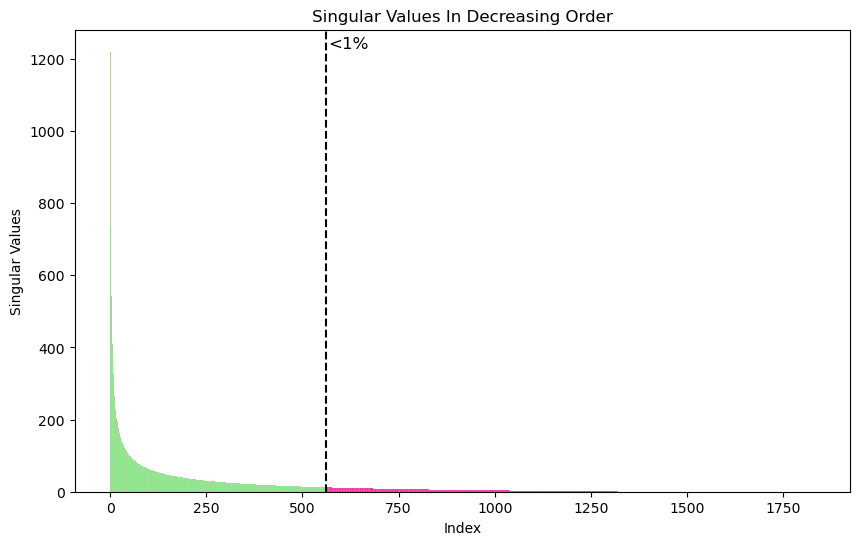

There are 560 singular values bigger than 1% of the first singular value (including the first)


In [4]:
# Calculate the singular values percentage
singular_values_percentage = (S / S[0]) * 100

# Plot the singular values
plt.figure(figsize=(10, 6))
plt.bar(np.arange(len(S)) + 1, S, color='deeppink', alpha=0.5, width=2.5)

# Highlight singular values bigger than 1% of the first singular value 
threshold = 1
green_indices = np.where(singular_values_percentage > threshold)[0]
plt.bar(green_indices + 1, S[green_indices], color='lightgreen', alpha=0.7, width=2.5)

# Add a vertical dashed line to separate the singular values
plt.axvline(x=len(green_indices) + 1, color='black', linestyle='--')

# Add text on the dashed line
plt.text(len(green_indices) + 60, max(S), '<1%', ha='center', va='bottom', color='black', fontsize=12)

plt.xlabel('Index')
plt.ylabel('Singular Values')
plt.title('Singular Values In Decreasing Order')
plt.show()

print(f"There are {len(green_indices)} singular values bigger than 1% of the first singular value (including the first)")

### Section D

Original normalized image size: 40201440 bytes


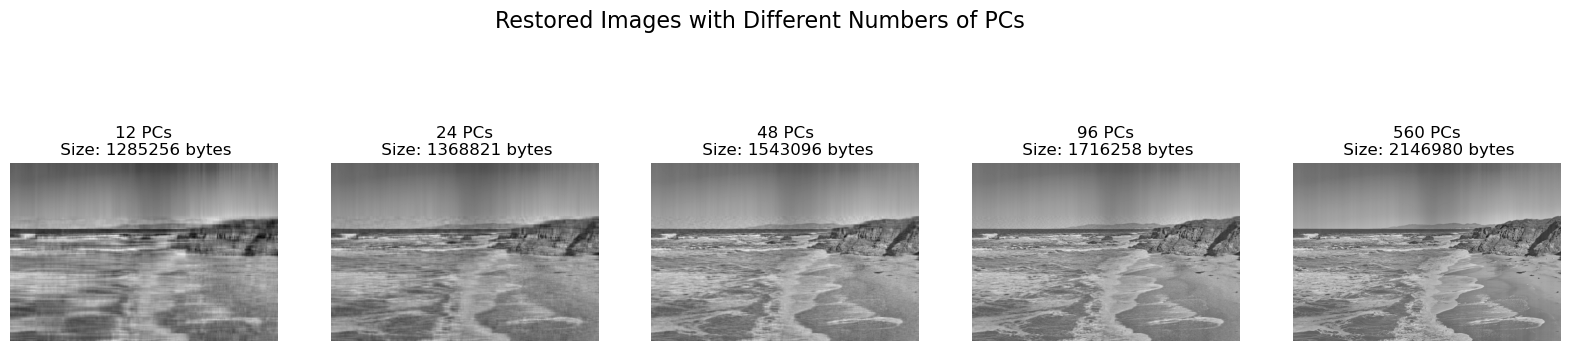

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import io
from PIL import Image

# Calculate the original size of the normalized image in bytes
original_size_bytes = normalized_gray_array.nbytes
print(f'Original normalized image size: {original_size_bytes} bytes')

# Number of PCs to use
pcs = [12, 24, 48, 96, len(green_indices)]

# Function to restore the image using a given number of principal components
def restore_image(U, S, Vt, num_pcs):
    U_reduced = U[:, :num_pcs]
    S_reduced = S[:num_pcs]
    Vt_reduced = Vt[:num_pcs, :]
    
    # Reconstruct the image
    restored_image = np.dot(U_reduced, np.dot(np.diag(S_reduced), Vt_reduced))
    
    # Normalize the restored image to fit in the 0-255 range
    restored_image_normalized = (restored_image - restored_image.min()) / (restored_image.max() - restored_image.min()) * 255
    
    return restored_image_normalized.astype(np.uint8)

# Function to calculate the compressed size of the image 
def calc_compressed_size(image_array):
    with io.BytesIO() as output:
        Image.fromarray(image_array).save(output, format='PNG')
        return output.tell()

# Plot the restored images
fig, axes = plt.subplots(1, len(pcs), figsize=(20, 5))
fig.suptitle('Restored Images with Different Numbers of PCs', size=16)

for i, num_pcs in enumerate(pcs):
    restored_image = restore_image(U, S, Vt, num_pcs)
    restored_size_bytes = calc_compressed_size(restored_image)
    axes[i].imshow(restored_image, cmap='gray')
    axes[i].set_title(f'{num_pcs} PCs\n Size: {restored_size_bytes} bytes')
    axes[i].axis('off')

plt.show()


**Is there any difference?**

It appears that a relatively low number of PCs (up to 24) managed to capture some of the image reasonably well.    


however, when compared to 560 PCs, there is a significant difference in terms of visual quality.

**Did the shrinking save a lot of memory in relation to the deterioration of the image quality?**

Yes, the shrinking saved a significant amount of memory, with the most compressed image (12 PCs) reducing the size by approximately 96.8%. However, this compression comes with a noticeable deterioration in image quality. Increasing the number of PCs improves image quality but also increases the file size, highlighting a trade-off between memory savings and visuality.